In [4]:
import os, re, csv, glob, random, subprocess, tempfile, json, string, difflib
from collections import Counter, defaultdict
from datetime import datetime
from PIL import Image, ImageFilter, ImageOps
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

In [43]:
# folder with your captcha pngs (change if needed)
FOLDER = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/training/data/varun"

# 4 directions used to measure how long a line run is: horizontal, vertical, 2 diagonals
DIRS = [(0, 1), (1, 0), (1, 1), (1, -1)]

PARAMS = dict(
    LETTER_MAX=35,  # pixel <= this counts as letter
    LEVEL_TOL=6,    # pixel within this of its line's gray counts as line core
    WIN=3,          # half-size of the window used to find the local line gray
    MAX_GAP=2,      # widest line cut (px) that gets bridged inside a letter
    SCALE=2,        # upscale factor
    THICKEN=3,      # MinFilter size, must be odd (1 = off)
    BLUR=0,       # Gaussian blur radius (0 = off)
    LINE_MIN=30,    # darkest gray allowed when estimating a line's gray
    BG_MIN=250,     # pixel >= this counts as background
    BORDER=40,      # white border added around the output
)

# random existing image path from the folder
def pick_image():
    files = glob.glob(os.path.join(FOLDER, "*.png"))
    if len(files) == 0:
        raise FileNotFoundError("no png files found in " + FOLDER)
    return random.choice(files)

# image file -> grayscale uint8 numpy array, shape (h, w)
def load(path):
    return np.array(Image.open(path).convert("L"))

# walk from (y, x) in one direction over line-core pixels (state 1)
# returns (steps taken, state of the pixel that ended the walk)
# if the run is longer than max_gap it gives up and returns 1
def _walk(state, y, x, dy, dx, max_gap):
    h, w = state.shape
    n = 0
    while True:
        y = y + dy
        x = x + dx
        if not (0 <= y < h and 0 <= x < w):
            return n, 0
        if state[y, x] != 1:
            return n, state[y, x]
        n = n + 1
        if n > max_gap:
            return n, 1

# stage 1: find the three masks (this is the part worth tuning)
def find_masks(a, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    a = a.astype(int)
    letters = a <= p["LETTER_MAX"]
    noise = (a > p["LETTER_MAX"]) & (a < p["BG_MIN"])
    r = p["WIN"]

    # for each noise pixel, the most common gray in its window = gray of the line through it
    level = np.zeros_like(a)
    for y, x in zip(*np.where(noise)):
        win = a[max(0, y - r):y + r + 1, max(0, x - r):x + r + 1]
        vals = win[(win > p["LINE_MIN"]) & (win < p["BG_MIN"])]
        if vals.size:
            v, c = np.unique(vals, return_counts=True)
            level[y, x] = v[np.argmax(c)]
    core = noise & (np.abs(a - level) <= p["LEVEL_TOL"])

    # 0 = background, 1 = line core, 2 = letter
    state = np.zeros_like(a)
    state[core] = 1
    state[letters] = 2

    # a line core pixel whose shortest run is <= MAX_GAP and has letter at both ends is a cut
    fill = np.zeros_like(core)
    for y, x in zip(*np.where(core)):
        best = None
        for dy, dx in DIRS:
            n1, e1 = _walk(state, y, x, dy, dx, p["MAX_GAP"])
            n2, e2 = _walk(state, y, x, -dy, -dx, p["MAX_GAP"])
            span = n1 + n2 + 1
            if best is None or span < best[0]:
                best = (span, e1, e2)
        if best[0] <= p["MAX_GAP"] and best[1] == 2 and best[2] == 2:
            fill[y, x] = True
    return letters, core, fill

# stage 2: boolean letter mask -> final image (upscale, thicken, blur, border)
def render(mask, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    im = Image.fromarray(np.where(mask, 0, 255).astype(np.uint8))
    im = im.resize((im.width * p["SCALE"], im.height * p["SCALE"]), Image.LANCZOS)
    if p["THICKEN"] > 1:
        im = im.filter(ImageFilter.MinFilter(p["THICKEN"]))
    if p["BLUR"]:
        im = im.filter(ImageFilter.GaussianBlur(p["BLUR"]))
    im = ImageOps.expand(im, border=p["BORDER"], fill=255)
    return np.array(im)

# grayscale array in, cleaned array out
def clean(a, **overrides):
    letters, core, fill = find_masks(a, **overrides)
    return render(letters | fill, **overrides)

# original | cleaned side by side. path=None picks a random image.
# steps=True also shows the intermediate masks. Returns the path so you can reuse it.
def compare(path=None, steps=False, **overrides):
    path = path or pick_image()
    a = load(path)
    letters, core, fill = find_masks(a, **overrides)
    c = render(letters | fill, **overrides)

    panels = list()
    panels.append(("original", a))
    if steps:
        panels.append(("letters only", np.where(letters, 0, 255)))
        panels.append(("line cores", np.where(core, 0, 255)))
        panels.append(("filled cuts", np.where(fill, 0, 255)))
    panels.append(("cleaned", c))

    fig, ax = plt.subplots(1, len(panels), figsize=(4 * len(panels), 2.5))
    ax = np.atleast_1d(ax)
    for axis, (title, img) in zip(ax, panels):
        axis.imshow(img, cmap="gray", vmin=0, vmax=255)
        axis.set_title(title)
        axis.axis("off")
    fig.suptitle(os.path.basename(path) + "   " + str(overrides))
    plt.show()
    return path

# one image, one setting varied: original on top, one cleaned version per value below
def tune(name, values, path=None, **overrides):
    path = path or pick_image()
    a = load(path)
    fig, ax = plt.subplots(len(values) + 1, 1, figsize=(5, 1.6 * (len(values) + 1)))
    ax[0].imshow(a, cmap="gray", vmin=0, vmax=255)
    ax[0].set_title("original " + os.path.basename(path))
    ax[0].axis("off")
    for i, v in enumerate(values):
        settings = dict(overrides)
        settings[name] = v
        ax[i + 1].imshow(clean(a, **settings), cmap="gray", vmin=0, vmax=255)
        ax[i + 1].set_title(name + " = " + str(v))
        ax[i + 1].axis("off")
    plt.tight_layout()
    plt.show()
    return path

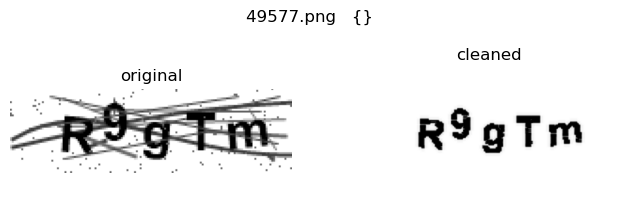

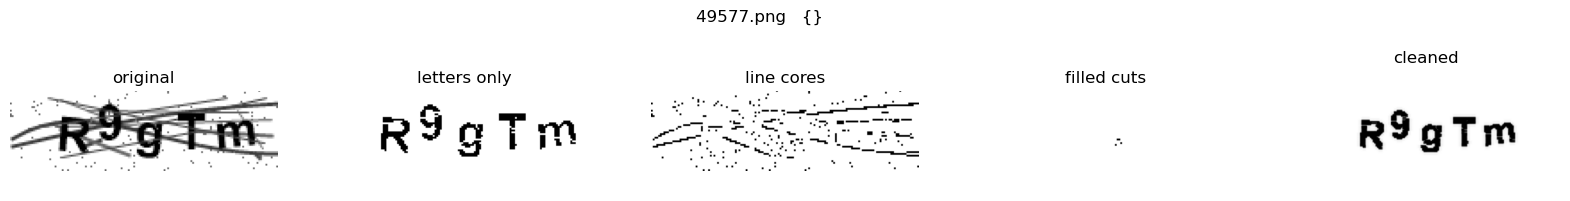

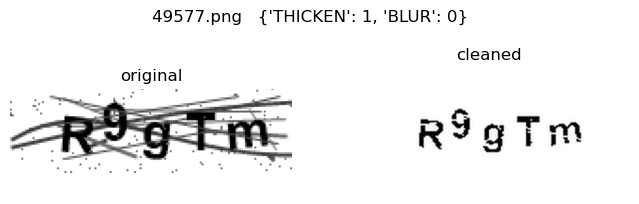

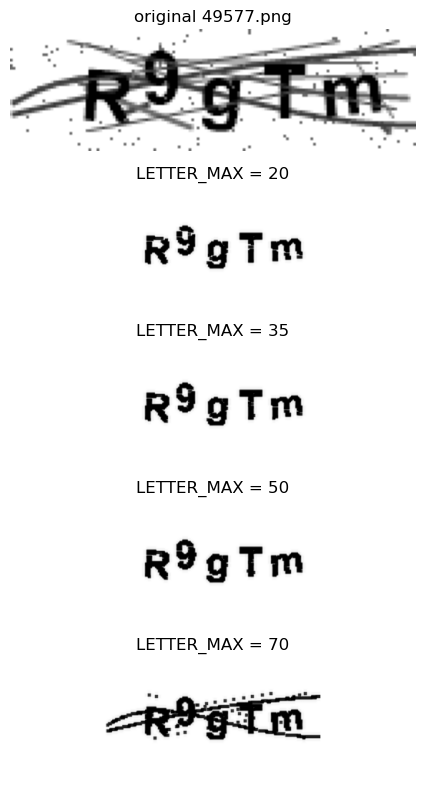

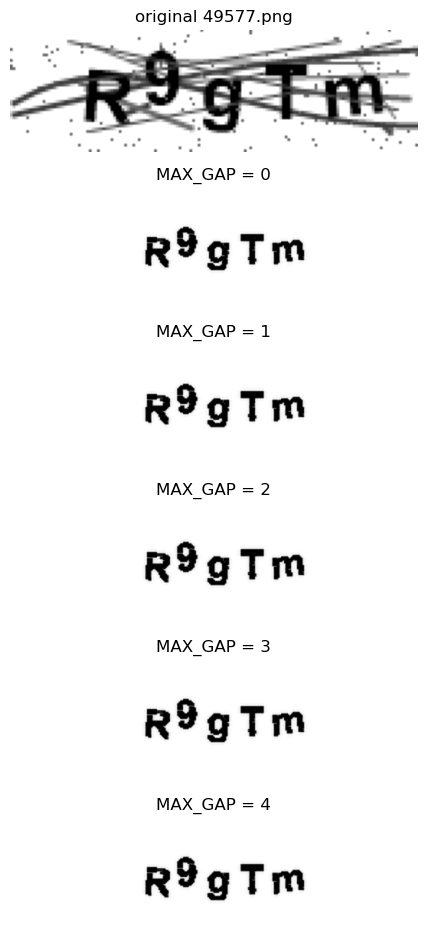

'/Users/varunmatta/Downloads/image_ftech_solver/varun/49577.png'

In [91]:
p = compare()                              # random image, original | cleaned
compare(p, steps=True)                     # same image, plus the intermediate masks
compare(p, THICKEN=1, BLUR=0)              # try other settings on that same image
tune("LETTER_MAX", [20, 35, 50, 70], p)    # sweep one setting
tune("MAX_GAP", [0, 1, 2, 3, 4], p, LETTER_MAX=50)  # sweep one, holding others changed

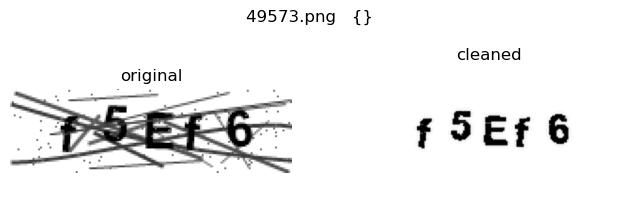

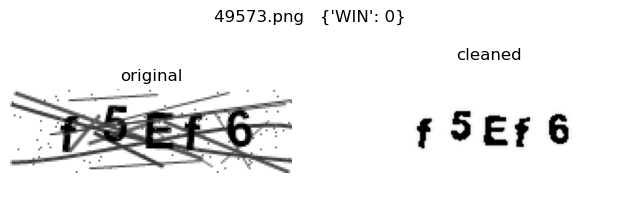

'/Users/varunmatta/Downloads/image_ftech_solver/varun/49573.png'

In [84]:
p = compare()    # random image, no blur
compare(p,WIN=0)
#compare(p, BLUR=0, THICKEN=1)
#tune("BLUR", [0, 0.5, 1, 1.5], p)

PARAMS = dict(


    WIN=3,          # half-size of the window used to find the local line gray
    MAX_GAP=2,      # widest line cut (px) that gets bridged inside a letter
    SCALE=2,        # upscale factor
    THICKEN=3,      # MinFilter size, must be odd (1 = off)
    BLUR=0,       # Gaussian blur radius (0 = off)
    LINE_MIN=30,    # darkest gray allowed when estimating a line's gray
    BG_MIN=250,     # pixel >= this counts as background
    BORDER=40,      # white border added around the output
)

In [92]:
import json, subprocess, tempfile, re, random

OCR = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/host/ocr"
LOG = "/Users/varunmatta/Drive/Varun/Projects/captcha_tester/data/ocr_review.json"
LENGTH = 5

# settings that change the mask (slow step). the rest only change rendering (fast step)
MASK_KEYS = ["LETTER_MAX", "LEVEL_TOL", "WIN", "MAX_GAP", "LINE_MIN", "BG_MIN"]

# reviewed images -> list of (image name, image array, true text)
def labeled_data():
    with open(LOG) as f:
        reviews = json.load(f)["reviews"]
    data = list()
    for img, r in reviews.items():
        path = os.path.join(FOLDER, img + ".png")
        data.append((img, load(path), r["truth"]))
    return data

# cleaned image arrays -> raw texts, one OCR call for all of them
def ocr_many(images):
    with tempfile.TemporaryDirectory() as tmp:
        paths = list()
        for i, c in enumerate(images):
            p = os.path.join(tmp, str(i) + ".png")
            Image.fromarray(c).save(p)
            paths.append(p)
        out = subprocess.run([OCR] + paths, capture_output=True, text=True, check=True).stdout
        got = dict()
        for line in out.splitlines():
            k, v = line.split("\t", 1)
            got[k] = v
        texts = list()
        for p in paths:
            texts.append(got.get(p, "").strip())
        return texts

# simple version of your restrict(): letters/digits only, at most 5
# (this skips your LOOKALIKE map, so scores may differ slightly from your old notebook)
def restrict(text):
    return re.sub(r"[^A-Za-z0-9]", "", text)[:LENGTH]

# find_masks is the slow part, so remember its result per (image, mask settings)
_cache = dict()

def get_mask(name, a, settings):
    key = [name]
    for k in MASK_KEYS:
        key.append(settings[k])
    key = tuple(key)
    if key not in _cache:
        letters, core, fill = find_masks(a, **settings)
        _cache[key] = letters | fill
    return _cache[key]

# one config -> (images read exactly right, characters right). higher is better
def score_config(data, settings):
    images = list()
    for name, a, truth in data:
        mask = get_mask(name, a, settings)
        images.append(render(tidy(mask, **settings), **settings))
    raws = ocr_many(images)
    exact = 0
    chars = 0
    for raw, (name, a, truth) in zip(raws, data):
        pred = restrict(raw)
        if pred == truth:
            exact = exact + 1
        for x, y in zip(pred, truth):
            if x == y:
                chars = chars + 1
    return (exact, chars)

# try every value of one setting at a time, keep improvements, repeat for `rounds`
def search(grid, rounds=2, test_frac=0.3):
    data = labeled_data()
    random.shuffle(data)
    cut = int(len(data) * (1 - test_frac))
    train = data[:cut]
    test = data[cut:]
    print(str(len(train)) + " train images, " + str(len(test)) + " held-out images")

    best = dict(PARAMS)
    best_score = score_config(train, best)
    print("start: train", best_score, "test", score_config(test, best))

    history = list()
    for r in range(rounds):
        changed = False
        for name, values in grid.items():
            for v in values:
                if v == best[name]:
                    continue
                trial = dict(best)
                trial[name] = v
                s = score_config(train, trial)
                history.append((name, v, s))
                if s > best_score:      # ties keep the current value
                    best = trial
                    best_score = s
                    changed = True
                    print("round " + str(r + 1) + ": " + name + " = " + str(v) + " -> train " + str(s))
        if not changed:
            break

    print("\nbest config:", best)
    print("train", best_score, "test", score_config(test, best))
    print("default on test:", score_config(test, dict(PARAMS)))
    return best, history

85 train images, 37 held-out images
start: train (40, 319) test (17, 146)
round 1: LETTER_MAX = 20 -> train (41, 315)
round 1: THICKEN = 5 -> train (42, 332)
round 1: BLUR = 1 -> train (42, 335)
round 1: MIN_BLOB = 0 -> train (46, 338)
round 2: LETTER_MAX = 35 -> train (48, 342)
round 2: THICKEN = 3 -> train (53, 350)
round 2: BLUR = 1.5 -> train (56, 362)
round 2: CLOSE = 0 -> train (64, 377)

best config: {'LETTER_MAX': 35, 'LEVEL_TOL': 6, 'WIN': 3, 'MAX_GAP': 2, 'SCALE': 2, 'THICKEN': 3, 'BLUR': 1.5, 'LINE_MIN': 30, 'BG_MIN': 250, 'BORDER': 40, 'CLOSE': 0, 'MIN_BLOB': 0}
train (64, 377) test (27, 170)
default on test: (17, 146)


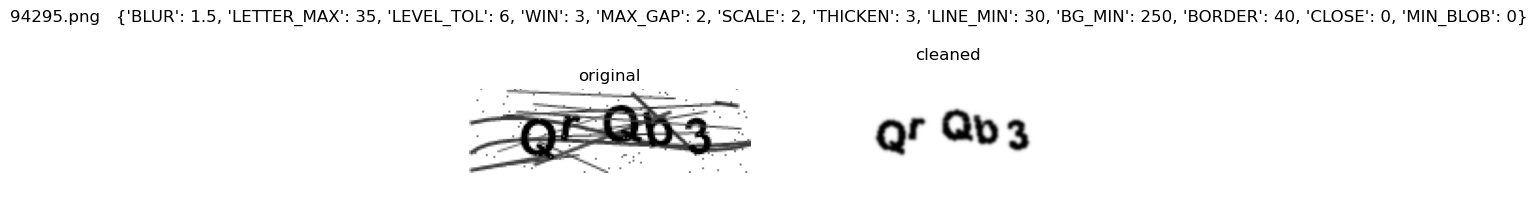

'/Users/varunmatta/Downloads/image_ftech_solver/varun/94295.png'

In [95]:
GRID = dict(
    LETTER_MAX=[20, 35, 50, 70],
    MAX_GAP=[1, 2, 3, 4],
    THICKEN=[1, 3, 5],
    BLUR=[0, 1, 1.5],
    CLOSE=[0, 1, 2],
    MIN_BLOB=[0, 8, 20],
)
best, history = search(GRID)
compare(BLUR=best["BLUR"], **{k: v for k, v in best.items() if k != "BLUR"})

In [94]:
from scipy import ndimage   # pip install scipy if missing

# add the two new settings without retyping PARAMS
PARAMS["CLOSE"] = 1      # radius of mask closing, heals small breaks (0 = off)
PARAMS["MIN_BLOB"] = 8   # drop connected blobs smaller than this many pixels (0 = off)

# post-process the boolean letter mask: heal small breaks, drop tiny specks
def tidy(mask, **overrides):
    p = dict(PARAMS)
    p.update(overrides)
    if p["CLOSE"] > 0:
        size = 2 * p["CLOSE"] + 1
        mask = ndimage.binary_closing(mask, structure=np.ones((size, size), dtype=bool))
    if p["MIN_BLOB"] > 0:
        labeled, count = ndimage.label(mask, structure=np.ones((3, 3)))
        keep = np.zeros(count + 1, dtype=bool)
        for k in range(1, count + 1):
            if (labeled == k).sum() >= p["MIN_BLOB"]:
                keep[k] = True
        mask = keep[labeled]
    return mask